# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DOSSIER = Path("donnees")
brut = pd.read_csv(DOSSIER / "consommation_brut.csv")
print("Forme :", brut.shape)
print("Types :")
display(brut.dtypes.to_frame("type"))
print("Valeurs manquantes :")
display(brut.isna().sum().to_frame("manquants"))
print("Lignes en double :", brut.duplicated().sum())

Matplotlib is building the font cache; this may take a moment.


Forme : (300, 4)
Types :


,type
mois,str
quartier,str
kwh,str
heures_courant,float64


Valeurs manquantes :


,manquants
mois,0
quartier,0
kwh,9
heures_courant,0


Lignes en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print("Nombre d'ecritures distinctes :", brut["quartier"].nunique())
print("Exemples :", brut["quartier"].drop_duplicates().head(10).tolist())

Nombre d'ecritures distinctes : 43
Exemples : ['Bas-Peu-de-Chose', 'bas-peu-de-chose', 'Bas-Peu-de-Chose ', ' Bas-Peu-de-Chose', 'BAS-PEU-DE-CHOSE', 'BOIS-VERNA', 'Bois-Verna', 'Centre-ville', 'centre-ville', 'Centre-ville ']


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
kwh_numerique_brut = pd.to_numeric(brut["kwh"], errors="coerce")
valeurs_non_convertibles = brut.loc[
    kwh_numerique_brut.isna() & brut["kwh"].notna(), "kwh"
].unique()
print("Valeurs non convertibles (hors vrais manquants) :")
print(valeurs_non_convertibles)

Valeurs non convertibles (hors vrais manquants) :
<ArrowStringArray>
['184410 kWh', '206280 kWh', '215140 kWh',    '251 900', '274520 kWh',
 '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh',
 '299610 kWh',    '373 880', '333670 kWh', '597730 kWh', '456060 kWh',
 '495020 kWh',    '409 300',    '556 070', '260360 kWh', '347870 kWh',
    '408 780',    '364 090', '243160 kWh',    '154 720',    '233 700',
    '253 300', '385840 kWh', '445270 kWh',    '337 810',    '366 390',
    '154 740', '170420 kWh', '201690 kWh',  '81370 kWh', '139470 kWh',
  '77670 kWh', '139230 kWh',    '121 240', '160110 kWh',    '105 830',
 '163010 kWh', '198720 kWh',    '281 240',    '104 640', '166700 kWh',
     '73 110',    '171 160', '187230 kWh']
Length: 48, dtype: str


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()
propre["kwh"] = propre["kwh"].str.replace("kWh", "", regex=False)
propre["kwh"] = propre["kwh"].str.replace(r"\s+", "", regex=True)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")
print("Valeurs manquantes apres conversion :", propre["kwh"].isna().sum())

Valeurs manquantes apres conversion : 9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
# Les noms officiels servent de reference; strip gere aussi les espaces en trop.
noms_officiels = pd.read_csv(DOSSIER / "quartiers.csv")["quartier"]
correspondance = {nom.strip().casefold(): nom for nom in noms_officiels}
propre["quartier"] = propre["quartier"].str.strip().str.casefold().map(correspondance)
print("Quartiers obtenus :", propre["quartier"].nunique())
print("Noms non reconnus :", propre["quartier"].isna().sum())

Quartiers obtenus : 12
Noms non reconnus : 0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
avant_dedoublonnage = len(propre)
propre = propre.drop_duplicates()
apres_dedoublonnage = len(propre)
propre = propre.dropna(subset=["kwh"]).reset_index(drop=True)
print("Doublons supprimes :", avant_dedoublonnage - apres_dedoublonnage)
print("Lignes sans kwh supprimees :", apres_dedoublonnage - len(propre))
print("Forme apres nettoyage :", propre.shape)

Doublons supprimes : 12
Lignes sans kwh supprimees : 9
Forme apres nettoyage : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
mediane_quartier = propre.groupby("quartier")["kwh"].transform("median")
valeurs_aberrantes = propre["kwh"] > 3 * mediane_quartier
print("Releves corriges :")
display(propre.loc[valeurs_aberrantes, ["mois", "quartier", "kwh"]])
propre.loc[valeurs_aberrantes, "kwh"] /= 10
propre["kwh"] = propre["kwh"].astype("int64")
propre = propre[["mois", "quartier", "kwh", "heures_courant"]]
print("Maximum apres correction :", propre["kwh"].max())
print("Forme finale du nettoyage :", propre.shape)

Releves corriges :


,mois,quartier,kwh
82,2025-02,Delmas 33,3602600.0
127,2025-02,Delmas 75,2012700.0
187,2024-02,Morne Calvaire,1439200.0
232,2024-01,Rue 15,997700.0


Maximum apres correction : 742780
Forme finale du nettoyage : (279, 4)


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
reference = pd.read_csv(DOSSIER / "consommation.csv")
reference = reference.merge(
    propre[["mois", "quartier"]],
    on=["mois", "quartier"],
    validate="one_to_one",
)
reference = reference[propre.columns].sort_values(["quartier", "mois"]).reset_index(drop=True)
propre_trie = propre.sort_values(["quartier", "mois"]).reset_index(drop=True)
print("Le nettoyage correspond au fichier de reference :", propre_trie.equals(reference))

Le nettoyage correspond au fichier de reference : True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
quartiers = pd.read_csv(DOSSIER / "quartiers.csv")
lignes_avant = len(propre)
avec_quartiers = propre.merge(quartiers, on="quartier", how="left", validate="many_to_one")
avec_quartiers["kwh_par_abonne"] = (avec_quartiers["kwh"] / avec_quartiers["abonnes"]).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)
print("Lignes avant/apres la jointure :", lignes_avant, len(avec_quartiers))
print("Bas-Peu-de-Chose, 2024-01 :", avec_quartiers.loc[
    (avec_quartiers["quartier"] == "Bas-Peu-de-Chose") & (avec_quartiers["mois"] == "2024-01"),
    "kwh_par_abonne",
].iloc[0], "kWh par abonne")

Lignes avant/apres la jointure : 279 279
Bas-Peu-de-Chose, 2024-01 : 85.8 kWh par abonne


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
meteo = pd.read_csv(DOSSIER / "meteo.csv")
lignes_avant = len(avec_quartiers)
avec_meteo = avec_quartiers.merge(
    meteo, on=["mois", "commune"], how="left", validate="many_to_one"
)
print("Lignes avant/apres la jointure :", lignes_avant, len(avec_meteo))
print("Temperatures manquantes :", avec_meteo["temperature_c"].isna().sum())

Lignes avant/apres la jointure : 279 279
Temperatures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
chemin_propre = DOSSIER / "consommation_propre.csv"
avec_meteo.to_csv(chemin_propre, index=False)
controle = pd.read_csv(chemin_propre)
print("Fichier ecrit :", chemin_propre)
print("Forme relue :", controle.shape)
print("Colonnes :", controle.columns.tolist())

Fichier ecrit : donnees\consommation_propre.csv
Forme relue : (279, 11)
Colonnes : ['mois', 'quartier', 'kwh', 'heures_courant', 'commune', 'type', 'abonnes', 'kwh_par_abonne', 'annee', 'temperature_c', 'pluie_mm']


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [12]:
moyennes_type = avec_meteo.groupby("type")["kwh_par_abonne"].mean().round(1)
classement = (
    avec_meteo.groupby("quartier")["kwh_par_abonne"]
    .mean()
    .sort_values(ascending=False)
    .round(1)
)
print("Moyenne mensuelle par abonne, selon le type :")
display(moyennes_type.to_frame("kWh par abonne"))
print("Classement des quartiers :")
display(classement.to_frame("kWh par abonne"))

Moyenne mensuelle par abonne, selon le type :


,kWh par abonne
type,
Commercial,393.2
Résidentiel,117.4


Classement des quartiers :


,kWh par abonne
quartier,
Centre-ville,468.7
Place Saint-Pierre,458.3
Delmas 33,374.4
Rue 15,268.5
Morne Calvaire,166.1
Thomassin,146.0
Delmas 65,134.9
Bois-Verna,130.1
Delmas 75,118.6


**Ce qu'on en conclut :** Les quartiers commerciaux consomment en moyenne 393,2 kWh par abonne et par mois, contre 117,4 pour les quartiers residentiels. Centre-ville arrive en tete (468,7), devant Place Saint-Pierre (458,3) et Delmas 33 (374,4).

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

,2024 (millions kWh),2025 (millions kWh),Hausse (%)
commune,,,
Cap-Haïtien,4.59,5.62,22.46
Pétion-Ville,8.60,9.68,12.56
Port-au-Prince,10.09,10.31,2.27
Delmas,11.61,11.74,1.10


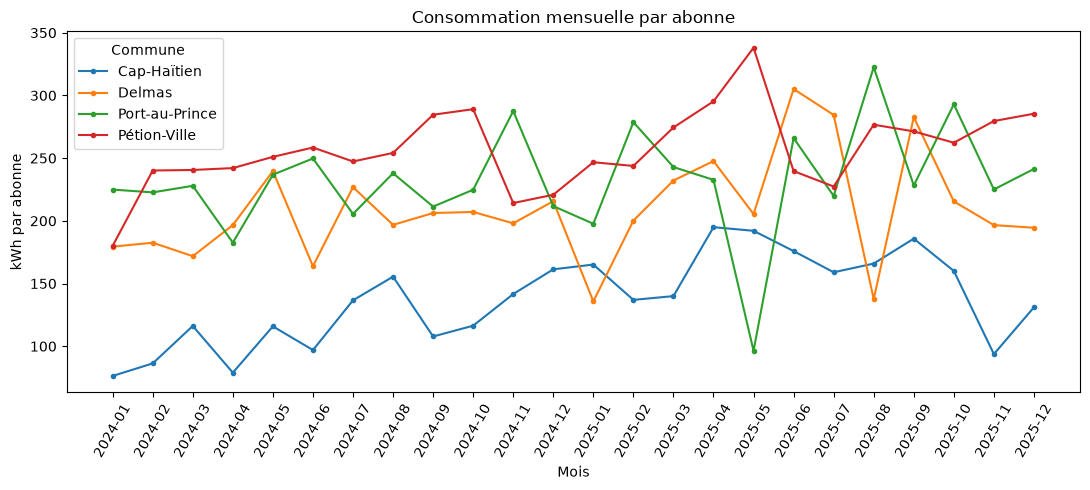

In [13]:
totaux_annuels = avec_meteo.pivot_table(
    index="commune", columns="annee", values="kwh", aggfunc="sum"
)
totaux_annuels["hausse_pct"] = (totaux_annuels[2025] / totaux_annuels[2024] - 1) * 100
resume_annuel = pd.DataFrame({
    "2024 (millions kWh)": totaux_annuels[2024] / 1_000_000,
    "2025 (millions kWh)": totaux_annuels[2025] / 1_000_000,
    "Hausse (%)": totaux_annuels["hausse_pct"],
}).sort_values("Hausse (%)", ascending=False).round(2)
display(resume_annuel)

mensuel = (
    avec_meteo.groupby(["mois", "commune"], as_index=False)["kwh_par_abonne"]
    .mean()
)
figure, axe = plt.subplots(figsize=(11, 5))
for commune, serie in mensuel.groupby("commune"):
    axe.plot(serie["mois"], serie["kwh_par_abonne"], marker=".", label=commune)
axe.set(title="Consommation mensuelle par abonne", xlabel="Mois", ylabel="kWh par abonne")
axe.tick_params(axis="x", labelrotation=60)
axe.legend(title="Commune")
figure.tight_layout()
plt.show()

**Ce qu'on en conclut :** Cap-Haitien connait la plus forte hausse entre 2024 et 2025, d'environ 22,5 % (4,59 a 5,62 millions de kWh). Delmas augmente le moins, de 1,1 %.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

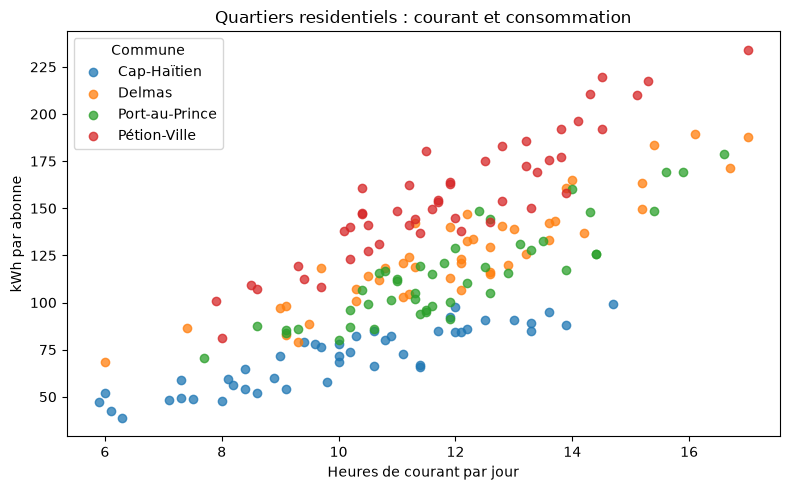

Correlation avec les heures de courant : 0.76
Correlation avec la temperature : -0.15


In [14]:
residentiel = avec_meteo[avec_meteo["type"].str.startswith("R")]
figure, axe = plt.subplots(figsize=(8, 5))
for commune, groupe in residentiel.groupby("commune"):
    axe.scatter(groupe["heures_courant"], groupe["kwh_par_abonne"], label=commune, alpha=0.75)
axe.set(title="Quartiers residentiels : courant et consommation", xlabel="Heures de courant par jour", ylabel="kWh par abonne")
axe.legend(title="Commune")
figure.tight_layout()
plt.show()
correlations = residentiel[["kwh_par_abonne", "heures_courant", "temperature_c"]].corr()["kwh_par_abonne"]
print(f"Correlation avec les heures de courant : {correlations['heures_courant']:.2f}")
print(f"Correlation avec la temperature : {correlations['temperature_c']:.2f}")

**Ce qu'on en conclut :** Dans les quartiers residentiels, la consommation varie fortement avec les heures de courant (correlation 0,76), mais tres peu avec la temperature (correlation -0,15). Cela indique une association, pas une preuve de causalite.

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

,mediane,Q1,Q3
commune,,,
Cap-Haïtien,10.0,8.3,11.7
Port-au-Prince,11.6,10.7,13.1
Pétion-Ville,11.6,10.4,13.0
Delmas,11.9,10.1,13.0


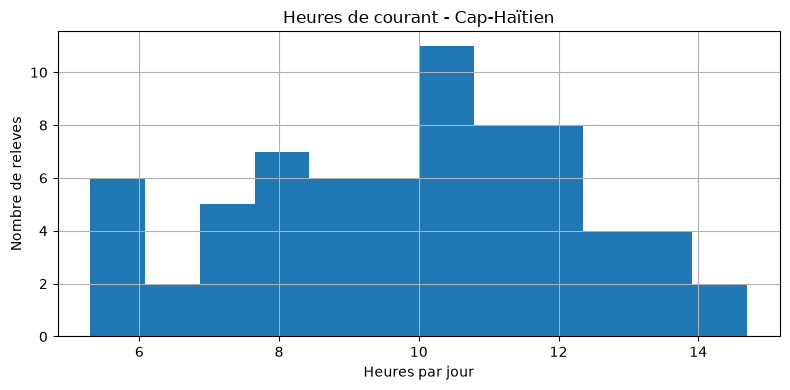

Releves 2025 avec moins de 8 heures : 3


,mois,quartier,commune,heures_courant
81,2025-01,Delmas 33,Delmas,7.4
227,2025-08,Carénage,Cap-Haïtien,7.3
253,2025-11,Rue 15,Cap-Haïtien,5.9


In [15]:
quartiles_heures = avec_meteo.groupby("commune")["heures_courant"].agg(
    mediane="median",
    Q1=lambda valeurs: valeurs.quantile(0.25),
    Q3=lambda valeurs: valeurs.quantile(0.75),
).round(1)
display(quartiles_heures.sort_values("mediane"))
commune_cap = avec_meteo["commune"].drop_duplicates().loc[
    avec_meteo["commune"].drop_duplicates().str.startswith("Cap-")
].iloc[0]
figure, axe = plt.subplots(figsize=(8, 4))
avec_meteo.loc[avec_meteo["commune"] == commune_cap, "heures_courant"].hist(bins=12, ax=axe)
axe.set(title=f"Heures de courant - {commune_cap}", xlabel="Heures par jour", ylabel="Nombre de releves")
figure.tight_layout()
plt.show()
peu_de_courant = avec_meteo[(avec_meteo["annee"] == 2025) & (avec_meteo["heures_courant"] < 8)]
print("Releves 2025 avec moins de 8 heures :", len(peu_de_courant))
display(peu_de_courant[["mois", "quartier", "commune", "heures_courant"]].sort_values("mois"))

**Ce qu'on en conclut :** Cap-Haitien a la mediane d'heures de courant la plus basse (10,0 h par jour), contre 11,6 a 11,9 h ailleurs. En 2025, trois releves passent sous 8 h : Carenage, Delmas 33 et Rue 15.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

,mois,quartier,type,kwh
0,2025-07,Delmas 33,Commercial,742780
1,2024-11,Centre-ville,Commercial,597730
2,2025-09,Delmas 33,Commercial,591420


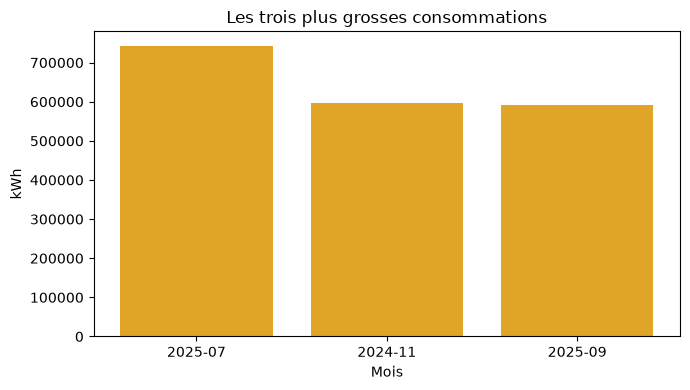

In [16]:
plus_gros = avec_meteo.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]
display(plus_gros.reset_index(drop=True))
figure, axe = plt.subplots(figsize=(7, 4))
axe.bar(plus_gros["mois"], plus_gros["kwh"], color="#e0a526")
axe.set(title="Les trois plus grosses consommations", xlabel="Mois", ylabel="kWh")
figure.tight_layout()
plt.show()

**Ce qu'on en conclut :** Les plus gros relev?s concernent Delmas 33 en juillet 2025 (742 780 kWh), Centre-ville en novembre 2024 (597 730 kWh), puis Delmas 33 en septembre 2025 (591 420 kWh).

## 9. Conclusion

La consommation par abonne des quartiers residentiels est davantage associee aux heures de courant (correlation de 0,76) qu'a la temperature (-0,15). L'analyse va donc dans le sens d'un lien plus fort avec la disponibilite du courant qu'avec la chaleur. Une correlation ne prouve toutefois pas que les heures de courant causent a elles seules la consommation : d'autres facteurs peuvent intervenir.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.